# Derivative-of-Gaussian Kernel Analysis

This notebook implements and compares different versions of the Derivative-of-Gaussian (DoG) kernel for discrete-time derivative estimation, based on the formulas from `root.tex`.

## Import Libraries

In [161]:
import numpy as np
import matplotlib.pyplot as plt


font_increase = 3

# Enable LaTeX rendering for matplotlib
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12 +font_increase  # Default font size
plt.rcParams['axes.labelsize'] = 12 +font_increase  # Axis labels
plt.rcParams['axes.titlesize'] = 14 +font_increase  # Title
plt.rcParams['xtick.labelsize'] = 10 +font_increase  # X-axis ticks
plt.rcParams['ytick.labelsize'] = 10 +font_increase  # Y-axis ticks
plt.rcParams['legend.fontsize'] = 11 +font_increase  # Legend

## Input Parameters

Set the cutoff frequency and sampling frequency. All other parameters are derived from these.

In [162]:
f_cut = 5.0  # Cutoff frequency in Hz
f_s = 200  # Sampling frequency in Hz
freq = 1  # Hz (frequency of sine wave for testing)
noise_amplitude = 0.1  # Amplitude of noise for sin wave

## Calculate Derived Parameters

From the paper formulas:
- $\sigma = \frac{1}{2\pi f_{\text{cut}}}$
- $N = 2K+1 = \lceil 6\sigma f_s \rceil$

In [163]:
# sigma = 1 / (2 * pi * f_cut)
sigma = 1 / (2 * np.pi * f_cut)

# N = ceil(6 * sigma * f_s)
N = int(np.ceil(6 * sigma * f_s))

# Ensure N is odd (2K+1 form)
if N % 2 == 0:
    N += 1

K = (N - 1) // 2  # Half-window size
dt = 1 / f_s  # Time step

print(f"Input Parameters:")
print(f"  f_cut = {f_cut:.2f} Hz")
print(f"  f_s = {f_s} Hz")
print(f"\nDerived Parameters:")
print(f"  sigma = {sigma:.6f}")
print(f"  N = {N} (window size)")
print(f"  K = {K} (half-window)")

Input Parameters:
  f_cut = 5.00 Hz
  f_s = 200 Hz

Derived Parameters:
  sigma = 0.031831
  N = 39 (window size)
  K = 19 (half-window)


## Non-Causal Kernel

Symmetric kernel centered at k=0:

$$h[k] = -\frac{t_k}{\sigma^3 \sqrt{2\pi}} \exp\left(-\frac{t_k^2}{2\sigma^2}\right) \cdot \Delta t$$

where $t_k = k \cdot \Delta t$ for $k \in [-K, K]$

In [164]:
k_noncausal = np.arange(-K, K + 1)  # k in [-K, K]
t_k = k_noncausal * dt

# h[k] = -(t_k / (sigma^3 * sqrt(2*pi))) * exp(-t_k^2 / (2*sigma^2))
# Multiply by dt to account for discrete approximation of the integral
h_noncausal = -(t_k / (sigma**3 * np.sqrt(2 * np.pi))) * np.exp(-t_k**2 / (2 * sigma**2)) * dt

## Causal Kernel Versions

We create multiple versions of the causal kernel to compare their performance:

1. **Truncated + Normalized**: The paper version with mean centering and L2 normalization
2. **Truncated Raw**: Just mean centering, no L2 normalization
3. **Shifted**: The non-causal kernel shifted by K samples (delayed but not truncated)

In [165]:
# First create h_c[k] = h[-k] for k in [0, 2K]
k_causal_raw = np.arange(0, 2*K + 1)  # k in [0, 2K]
t_k_causal_raw = -k_causal_raw * dt  # We use h[-k], so negative time

h_causal_raw = -(t_k_causal_raw / (sigma**3 * np.sqrt(2 * np.pi))) * np.exp(-t_k_causal_raw**2 / (2 * sigma**2)) * dt

# Version 1: Truncated raw (no processing)
h_causal_unnormalized = h_causal_raw.copy()

# Version 2: Shifted non-causal kernel (no truncation)
h_causal_shifted = h_noncausal.copy()

# Version 3: Truncated with mean removal and L2 normalization (paper version)
h_bar = np.mean(h_causal_raw)
h_tilde = h_causal_raw - h_bar
E = np.sqrt(np.sum(h_tilde**2))
h_causal = h_tilde / E

## Plot: Kernel Comparison

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.



Saved kernel comparison plot to kernel_comparison.eps


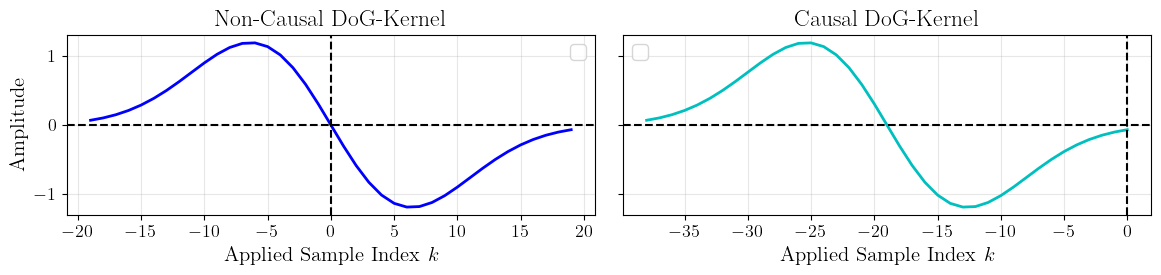

In [209]:
#fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))
fig, (ax1, ax4) = plt.subplots(1, 2, figsize=(12, 3), sharey=True)

# Non-causal kernel
ax1.plot(k_noncausal, h_noncausal, 'b-', linewidth=2)
ax1.axhline(y=0, color='k', linestyle='--', linewidth=1.5)
ax1.axvline(x=0, color='k', linestyle='--', linewidth=1.5)
ax1.grid(True, alpha=0.3)
ax1.set_xlabel('Applied Sample Index $k$')
ax1.set_ylabel('Amplitude')
ax1.set_title(f'Non-Causal DoG-Kernel')
ax1.legend()

# # Causal kernel (normalized)
# ax2.plot(-k_causal_raw, h_causal, 'r-', linewidth=2, label='Truncated + zero-mean + L2-normalized')
# ax2.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
# ax2.grid(True, alpha=0.3)
# ax2.set_xlabel('Sample index $k$')
# ax2.set_ylabel('Amplitude')
# ax2.set_title('Causal: Truncated, Mean-Removed, Normalized')
# ax2.legend()

# # Causal kernel (raw, no normalization)
# ax3.plot(-k_causal_raw, h_causal_unnormalized, 'm-', linewidth=2, label='Truncated')
# ax3.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
# ax3.grid(True, alpha=0.3)
# ax3.set_xlabel('Sample index $k$')
# ax3.set_ylabel('Amplitude')
# ax3.set_title('Causal: Truncated Only (No Processing)')
# ax3.legend()

# Causal kernel (shifted, not truncated)
ax4.plot(-(k_noncausal + K), -h_causal_shifted, 'c-', linewidth=2)
ax4.axhline(y=0, color='k', linestyle='--', linewidth=1.5)
ax4.axvline(x=0, color='k', linestyle='--', linewidth=1.5)
ax4.grid(True, alpha=0.3)
ax4.set_xlabel('Applied Sample Index $k$')
#ax4.set_ylabel('Amplitude')
ax4.set_title('Causal DoG-Kernel')
ax4.legend()

plt.tight_layout()
plt.savefig('/home/fabi/catkin_ws/src/ros_imu_calib/pub/img/kernel_comparison.eps', format='eps', dpi=600)
print("\nSaved kernel comparison plot to kernel_comparison.eps")
plt.show()

## Generate Test Signal

Create a sine wave and compute its analytical derivative for comparison.

In [167]:
# Create a clean sine wave sampled at 200 Hz
duration = 7.0  # seconds
t = np.arange(0, duration, dt)
x_clean = np.sin(2 * np.pi * freq * t)

# Add high frequency noise
np.random.seed(42)  # For reproducibility
noise = noise_amplitude * np.random.randn(len(t))
x = x_clean + noise

# Analytical derivative: d/dt[sin(2*pi*f*t)] = 2*pi*f*cos(2*pi*f*t)
# This is the derivative of the CLEAN signal
dx_dt_true = 2 * np.pi * freq * np.cos(2 * np.pi * freq * t)

## Manual Convolution

Implement the convolution using explicit loops as per the formulas in the paper:

**Non-causal:**
$$\frac{\partial x[n]}{\partial t} = \sum_{k=-K}^{K} h[k] \cdot x[n-k]$$

**Causal:**
$$\frac{\partial x[n]}{\partial t} = \sum_{k=-K}^{K} h[k] \cdot x[n-k-K]$$


In [176]:
# Manual convolution with non-causal kernel
# Formula: dx/dt[n] = sum_{k=-K}^{K} h[k] * x[n-k]
dx_dt_noncausal = np.zeros_like(x)
for n in range(len(x)):
    for k in range(-K, K + 1):
        idx = n - k
        if 0 <= idx < len(x):
            dx_dt_noncausal[n] += h_noncausal[k + K] * x[idx]

# Manual convolution with causal kernel (normalized)
# Formula: dx/dt[n] = sum_{k=0}^{2K} h_c[k] * x[n-k]
dx_dt_causal = np.zeros_like(x)
for n in range(len(x)):
    for k in range(0, 2*K + 1):
        idx = n - k
        if 0 <= idx < len(x):
            dx_dt_causal[n] += h_causal[k] * x[idx]

# Manual convolution with unnormalized causal kernel
dx_dt_causal_unnorm = np.zeros_like(x)
for n in range(len(x)):
    for k in range(0, 2*K + 1):
        idx = n - k
        if 0 <= idx < len(x):
            dx_dt_causal_unnorm[n] += h_causal_unnormalized[k] * x[idx]

# Manual convolution with shifted (non-truncated) causal kernel
# This applies the full non-causal kernel but shifted by K samples (delayed)
dx_dt_causal_shifted = np.zeros_like(x)
for n in range(len(x)):
    for k in range(-K, K + 1):
        idx = n - k - K  # Shift by K to make it causal
        if 0 <= idx < len(x):
            dx_dt_causal_shifted[n] += h_causal_shifted[k + K] * x[idx]

# Finite differences (central) for comparison
dx_dt_fd = np.gradient(x, dt)

## Plot: Derivative Comparison

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved derivative comparison plot to derivative_comparison.eps


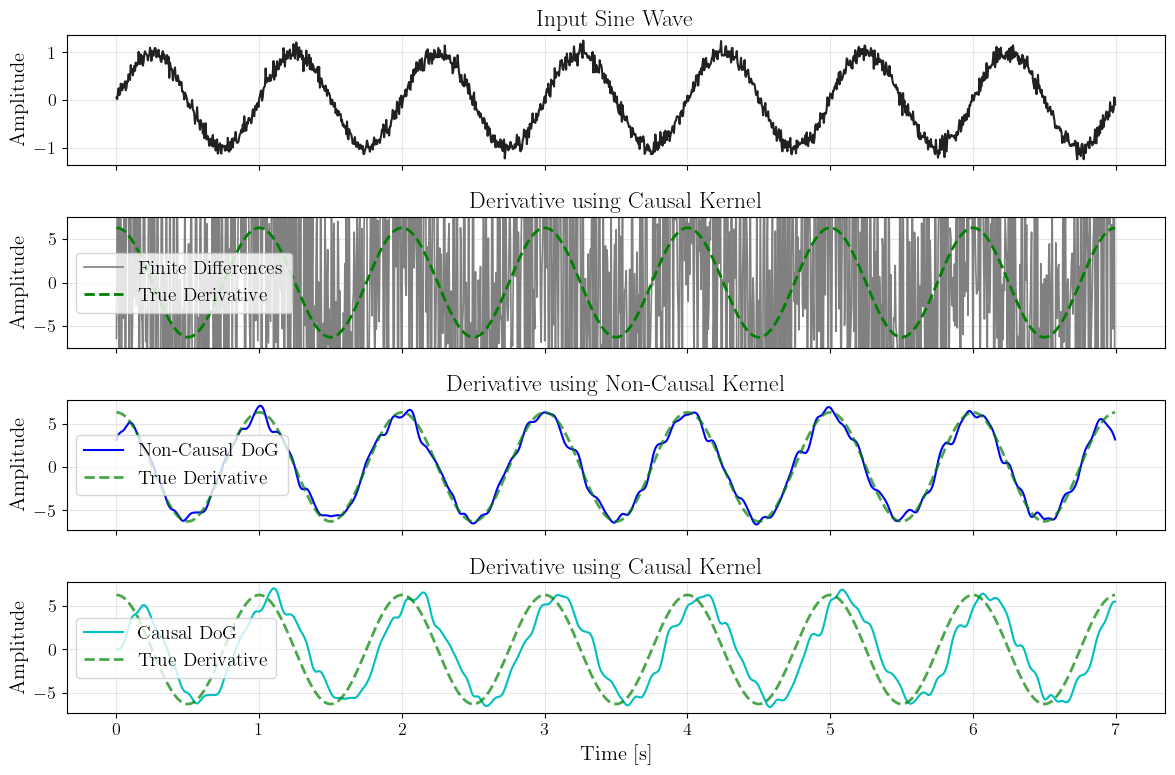

In [210]:
# fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(5, 1, figsize=(12, 14))
fig, (ax1, ax2, ax5, ax6) = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

# Plot 1: Original signal (showing both clean and noisy)
ax1.plot(t, x, color='0.13')
ax1.grid(True, alpha=0.3)
#ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Amplitude')
ax1.set_title('Input Sine Wave')

# Plot 2: Derivative using non-causal kernel
ax2.plot(t, dx_dt_fd, color='0.5', linewidth=1.2, label='Finite Differences')
ax2.plot(t, dx_dt_true, 'g--', linewidth=2, label='True Derivative')
ax2.grid(True, alpha=0.3)
ax2.set_ylabel('Amplitude')
ax2.set_ylim([-7.5, 7.5])
ax2.set_title('Derivative using Causal Kernel')
ax2.legend()

# # Plot 3: Derivative using causal kernel
# ax3.plot(t, dx_dt_true, 'g-', linewidth=2, alpha=0.7, label='True derivative (clean signal)')
# ax3.plot(t, dx_dt_causal, 'r--', linewidth=1.5, label='Causal DoG on noisy signal (normalized)')
# ax3.grid(True, alpha=0.3)
# ax3.set_xlabel('Time [s]')
# ax3.set_ylabel('Derivative')
# ax3.set_title('Derivative using Causal Kernel (mean-removed, L2-normalized)')
# ax3.legend()

# # Plot 4: Derivative using unnormalized causal kernel
# ax4.plot(t, dx_dt_true, 'g-', linewidth=2, alpha=0.7, label='True derivative (clean signal)')
# ax4.plot(t, dx_dt_causal_unnorm, 'm--', linewidth=1.5, label='Causal DoG on noisy signal (raw)')
# ax4.grid(True, alpha=0.3)
# ax4.set_xlabel('Time [s]')
# ax4.set_ylabel('Derivative')
# ax4.set_title('Derivative using Causal Kernel (truncated, no processing)')
# ax4.legend()

# Plot 5: Derivative using shifted (non-truncated) causal kernel
ax5.plot(t, dx_dt_noncausal, 'b-', linewidth=1.5, label='Non-Causal DoG')
ax5.plot(t, dx_dt_true, 'g--', linewidth=2, alpha=0.7, label='True Derivative')
ax5.grid(True, alpha=0.3)
#ax2.set_xlabel('Time [s]')
ax5.set_ylabel('Amplitude')
ax5.set_title('Derivative using Non-Causal Kernel')
ax5.legend()

ax6.plot(t, dx_dt_causal_shifted, 'c-', linewidth=1.5, label='Causal DoG')
ax6.plot(t, dx_dt_true, 'g--', linewidth=2, alpha=0.7, label='True Derivative')
ax6.grid(True, alpha=0.3)
ax6.set_xlabel('Time [s]')
ax6.set_ylabel('Amplitude')
ax6.set_title('Derivative using Causal Kernel')
ax6.legend()

plt.tight_layout()
plt.savefig('/home/fabi/catkin_ws/src/ros_imu_calib/pub/img/derivative_comparison.eps', format='eps', dpi=600)
print("Saved derivative comparison plot to derivative_comparison.eps")
plt.show()

## Error Analysis

Calculate RMSE for each kernel version.

In [ ]:
# Calculate errors
error_noncausal = np.sqrt(np.mean((dx_dt_true - dx_dt_noncausal)**2))
error_causal = np.sqrt(np.mean((dx_dt_true - dx_dt_causal)**2))
error_causal_unnorm = np.sqrt(np.mean((dx_dt_true - dx_dt_causal_unnorm)**2))
error_causal_shifted = np.sqrt(np.mean((dx_dt_true - dx_dt_causal_shifted)**2))
error_fd = np.sqrt(np.mean((dx_dt_true - dx_dt_fd)**2))

print(f"\nRMSE:")
print(f"  Non-causal kernel:\t\t\t {error_noncausal:.6f}")
print(f"  Causal kernel (truncated, normalized): {error_causal:.6f}")
print(f"  Causal kernel (truncated):\t\t {error_causal_unnorm:.6f}")
print(f"  Causal kernel (shifted):\t\t {error_causal_shifted:.6f}")
print(f"  Finite difference:\t\t\t {error_fd:.6f}")


RMSE:
  Non-causal kernel:			 0.571080
  Causal kernel (truncated, normalized): 3.577154
  Causal kernel (truncated):		 10.763404
  Causal kernel (shifted):		 2.668121
